In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import joblib

# Path is relative to the notebooks/ folder
DATA_PATH = Path("../data/raw/household_power_consumption.txt")
print("File exists:", DATA_PATH.exists())

Matplotlib is building the font cache; this may take a moment.


File exists: True


In [5]:
# Load the dataset without parse_dates (newer pandas doesn't accept dict here)
df = pd.read_csv(
    DATA_PATH,
    sep=";",
    na_values="?",
    low_memory=False,
)

print("Raw shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())


# Cell 2b: Combine Date and Time into datetime index
df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)
df = df.drop(columns=["Date", "Time"]).set_index("datetime")
df = df.dropna(subset=["datetime"] if "datetime" in df.columns else [])
print("Shape after datetime index:", df.shape)
print("First timestamp:", df.index[0])
print("Last timestamp:", df.index[-1])

Raw shape: (2075259, 9)
Columns: ['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


Shape after datetime index: (2075259, 7)
First timestamp: 2006-12-16 17:24:00
Last timestamp: 2010-11-26 21:02:00


In [6]:
# Cell 3: Clean and format
df = df.dropna(subset=["Global_active_power"])
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df = df.interpolate(method="linear", limit=60)
print("After cleaning:", df.shape)
print("Remaining NaNs:", df.isna().sum().sum())

After cleaning: (2049280, 7)
Remaining NaNs: 0


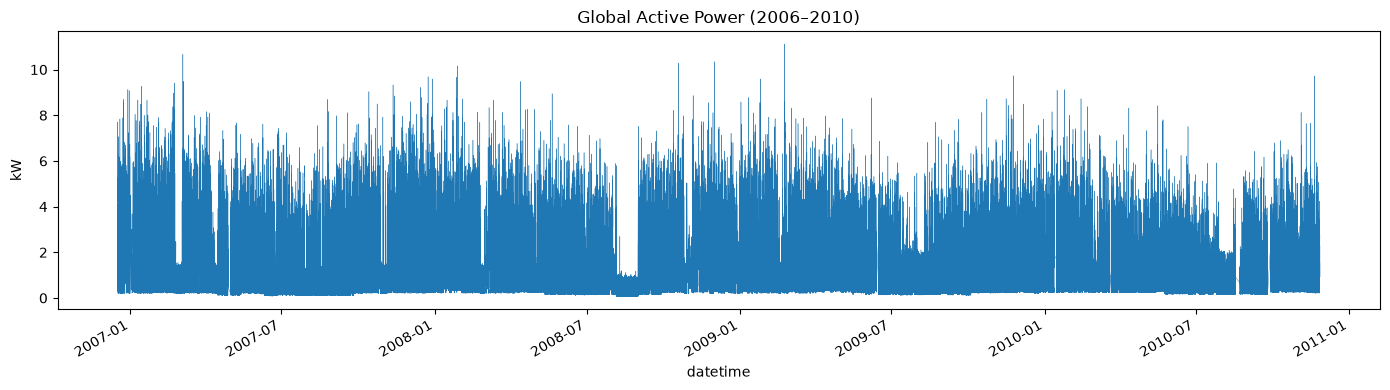

In [7]:
# Cell 4: Quick plot
fig, ax = plt.subplots(figsize=(14, 4))
df["Global_active_power"].plot(ax=ax, linewidth=0.3)
ax.set_title("Global Active Power (2006–2010)")
ax.set_ylabel("kW")
plt.tight_layout()
plt.show()

In [8]:
# Cell 5: Resample to hourly
df_hourly = df.resample("1h").mean()
df_hourly = df_hourly.dropna()
print("Hourly shape:", df_hourly.shape)
display(df_hourly.head())

Hourly shape: (34168, 7)


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,0.527778,16.861111
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,6.716667,16.866667
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,1.433333,16.683333
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.000000,16.783333
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,0.416667,17.216667


In [9]:
# Cell 6: Save processed data
df_hourly.to_csv("../data/processed/hourly_power.csv")
print("Saved to data/processed/hourly_power.csv")

Saved to data/processed/hourly_power.csv


In [10]:
def create_windows(series, window_size=24, horizon=1):
    """
    Build (X, y) windows.
    X: past `window_size` hours
    y: value `horizon` hours ahead
    """
    X, y = [], []
    values = series.values
    for i in range(len(values) - window_size - horizon + 1):
        X.append(values[i : i + window_size])
        y.append(values[i + window_size + horizon - 1])
    return np.array(X), np.array(y)

# Target variable: Global_active_power
target = df_hourly["Global_active_power"]
X, y = create_windows(target, window_size=24, horizon=1)

print("X shape:", X.shape)   # Expect (~34144, 24)
print("y shape:", y.shape)   # Expect (~34144,)

X shape: (34144, 24)
y shape: (34144,)


In [11]:
n = len(X)
train_end = int(0.70 * n)
val_end   = int(0.85 * n)

X_train, y_train = X[:train_end], y[:train_end]
X_val,   y_val   = X[train_end:val_end], y[train_end:val_end]
X_test,  y_test  = X[val_end:], y[val_end:]

print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

Train: (23900, 24), Val: (5122, 24), Test: (5122, 24)


In [12]:
from sklearn.preprocessing import MinMaxScaler
import joblib

scaler = MinMaxScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

# Save the scaler for the FastAPI API later
joblib.dump(scaler, "../models/scaler.pkl")
print("Scaler saved to models/scaler.pkl")

Scaler saved to models/scaler.pkl


In [13]:
np.save("../data/processed/X_train.npy", X_train_s)
np.save("../data/processed/y_train.npy", y_train)
np.save("../data/processed/X_val.npy", X_val_s)
np.save("../data/processed/y_val.npy", y_val)
np.save("../data/processed/X_test.npy", X_test_s)
np.save("../data/processed/y_test.npy", y_test)
print("All splits saved to data/processed/")

All splits saved to data/processed/
